In [1]:

# Import essential libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

# Load the Netflix dataset

df = pd.read_csv('/content/netflix_titles.csv')

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [4]:

# Check files in the Colab directory

import os

print(os.listdir('/content/'))


['.config', 'netflix_titles.csv', 'netflix_titles.csv.zip', 'sample_data']


In [8]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:

# Check the dimensions of the dataset

print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (8807, 12)
Total Rows: 8807
Total Columns: 12


In [10]:

# Display all column names

print("Netflix Dataset Columns:")
print(df.columns.tolist())


Netflix Dataset Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [11]:

# Display dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [13]:
missing_values = df.isnull().sum()
print(missing_values)

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [14]:

# Calculate missing value percentages

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))


Missing Value Percentage:
show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64


In [15]:

# Generate descriptive statistics

df.describe()


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [16]:

# Create a copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")


Working copy created successfully!


In [17]:

# Handle missing values in text columns

df_clean['director'] = df_clean['director'].fillna('Not Specified')

df_clean['cast'] = df_clean['cast'].fillna('Not Specified')

df_clean['country'] = df_clean['country'].fillna('Not Specified')

print("Missing values handled in director, cast and country!")


Missing values handled in director, cast and country!


In [18]:

# Check missing values in cleaned columns

print(df_clean[['director', 'cast', 'country']].isnull().sum())

director    0
cast        0
country     0
dtype: int64


In [20]:

# Handle missing values in rating and duration

df_clean['rating'] = df_clean['rating'].fillna('Not Specified')

df_clean['duration'] = df_clean['duration'].fillna('Not Specified')

print("Missing values handled in rating and duration!")


Missing values handled in rating and duration!


In [21]:

# Convert date_added into datetime format

df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    errors='coerce'
)

print("date_added converted into datetime format!")


date_added converted into datetime format!


In [22]:

# Verify remaining missing values and data types

print("Missing values:")
print(df_clean[['rating', 'duration', 'date_added']].isnull().sum())

print("\nData types:")
print(df_clean[['rating', 'duration', 'date_added']].dtypes)



Missing values:
rating         0
duration       0
date_added    98
dtype: int64

Data types:
rating                object
duration              object
date_added    datetime64[ns]
dtype: object


In [23]:

# Correctly convert date_added into datetime

df_clean['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    format='mixed',
    errors='coerce'
)

print("Date conversion corrected!")


Date conversion corrected!


In [24]:

# Verify date conversion

print("Missing dates:", df_clean['date_added'].isnull().sum())

print("Data type:", df_clean['date_added'].dtype)



Missing dates: 10
Data type: datetime64[ns]


In [25]:

# Check for duplicate records

duplicates = df_clean.duplicated().sum()

print("Total Duplicate Records:", duplicates)


Total Duplicate Records: 0


In [26]:

# Final verification of cleaned dataset

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values in Cleaned Dataset:")
print(df_clean.isnull().sum())

print("\nTotal Duplicate Records:", df_clean.duplicated().sum())


Original Dataset Shape: (8807, 12)
Cleaned Dataset Shape: (8807, 12)

Missing Values in Cleaned Dataset:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Total Duplicate Records: 0


In [27]:

# Count Movies and TV Shows

content_counts = df_clean['type'].value_counts()

print("Netflix Content Distribution:")
print(content_counts)


Netflix Content Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


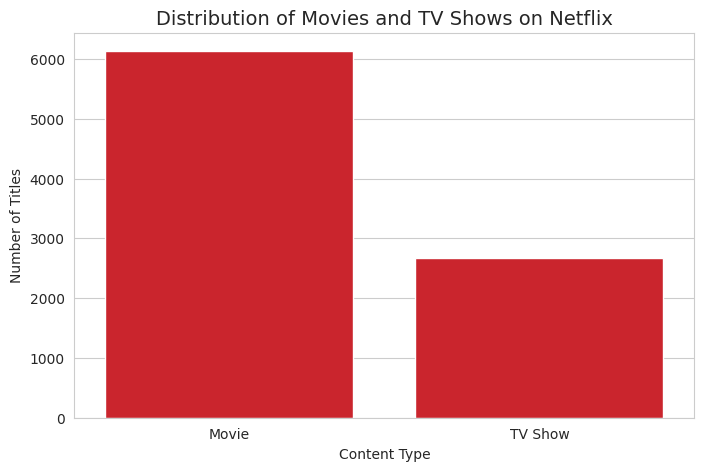

In [28]:

# Visualization 1: Movies vs TV Shows

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='type',
    order=content_counts.index,
    color='#E50914'
)

plt.title('Distribution of Movies and TV Shows on Netflix',
          fontsize=14)

plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.show()


In [29]:

# Separate multiple countries into individual rows

countries = df_clean['country'].str.split(',')

countries = countries.explode()

countries = countries.str.strip()

print("Country separation completed!")

print(countries.head(10))


Country separation completed!
0    United States
1     South Africa
2    Not Specified
3    Not Specified
4            India
5    Not Specified
6    Not Specified
7    United States
7            Ghana
7     Burkina Faso
Name: country, dtype: object


In [30]:

# Find the top 10 countries with the most Netflix titles

top_countries = countries[
    countries != 'Not Specified'
].value_counts().head(10)

print("Top 10 Countries on Netflix:")
print(top_countries)


Top 10 Countries on Netflix:
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


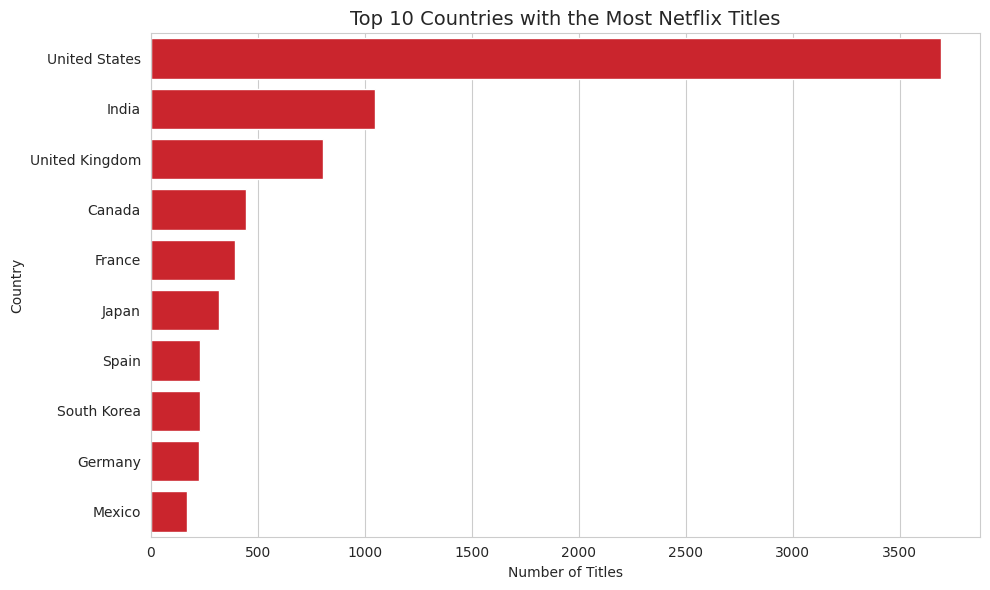

In [31]:

# Visualization 2: Top 10 countries

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    color='#E50914'
)

plt.title('Top 10 Countries with the Most Netflix Titles',
          fontsize=14)

plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.tight_layout()

plt.show()


In [32]:

# Count Netflix titles by release year

year_counts = df_clean['release_year'].value_counts().sort_index()

print("Netflix Titles by Release Year:")
print(year_counts.tail(15))


Netflix Titles by Release Year:
release_year
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


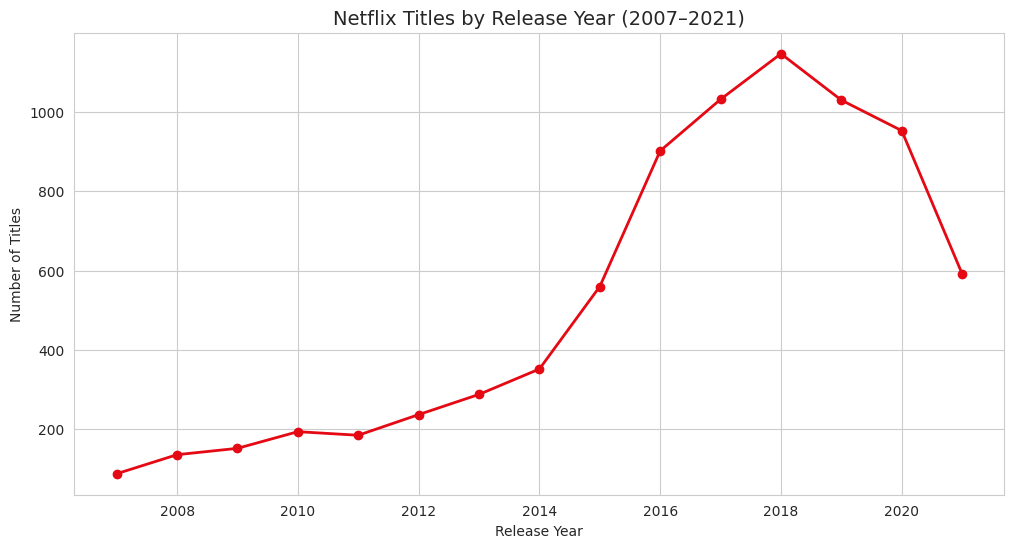

In [33]:

# Visualization 3: Netflix titles released over the years

plt.figure(figsize=(12, 6))

plt.plot(
    year_counts.loc[2007:2021].index,
    year_counts.loc[2007:2021].values,
    marker='o',
    color='#E50914',
    linewidth=2
)

plt.title('Netflix Titles by Release Year (2007–2021)',
          fontsize=14)

plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(True)

plt.show()


In [34]:

# Separate genres into individual rows

genres = df_clean['listed_in'].str.split(',')

genres = genres.explode()

genres = genres.str.strip()

print("Genre separation completed!")

print(genres.head(10))


Genre separation completed!
0             Documentaries
1    International TV Shows
1                 TV Dramas
1              TV Mysteries
2            Crime TV Shows
2    International TV Shows
2     TV Action & Adventure
3                Docuseries
3                Reality TV
4    International TV Shows
Name: listed_in, dtype: object


In [35]:

# Find the top 10 most common Netflix genres

top_genres = genres.value_counts().head(10)

print("Top 10 Netflix Genres:")
print(top_genres)


Top 10 Netflix Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


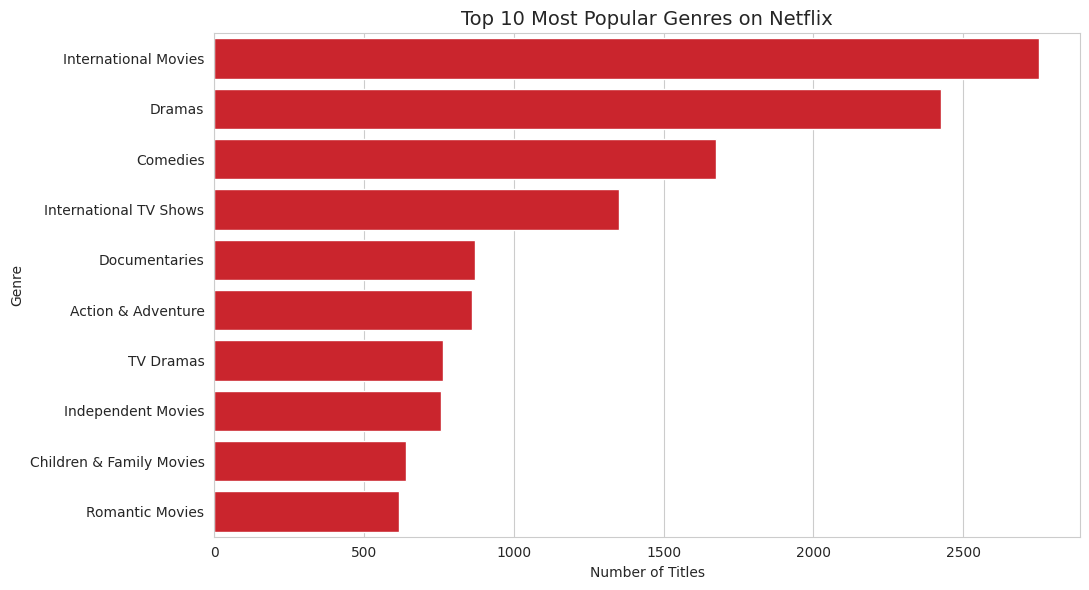

In [36]:

# Visualization 4: Top 10 Netflix Genres

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    color='#E50914'
)

plt.title('Top 10 Most Popular Genres on Netflix',
          fontsize=14)

plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.tight_layout()

plt.show()


In [37]:

# Count Netflix content ratings

rating_counts = df_clean['rating'].value_counts()

print("Netflix Content Rating Distribution:")
print(rating_counts.head(15))


Netflix Content Rating Distribution:
rating
TV-MA            3207
TV-14            2160
TV-PG             863
R                 799
PG-13             490
TV-Y7             334
TV-Y              307
PG                287
TV-G              220
NR                 80
G                  41
TV-Y7-FV            6
Not Specified       4
NC-17               3
UR                  3
Name: count, dtype: int64


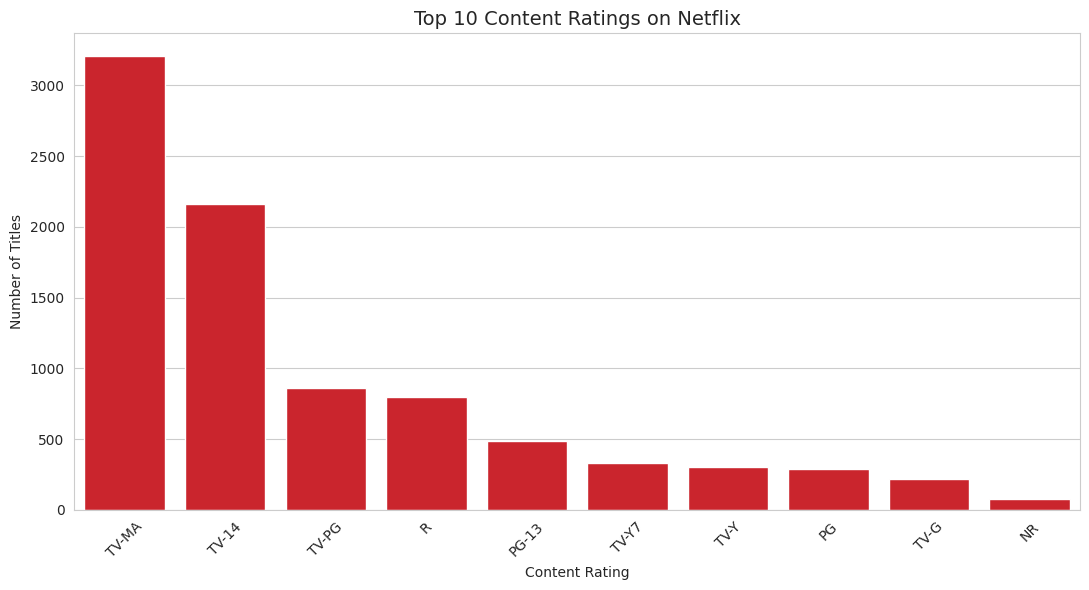

In [38]:

# Visualization 5: Top 10 Netflix Content Ratings

top_ratings = rating_counts[
    rating_counts.index != 'Not Specified'
].head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_ratings.index,
    y=top_ratings.values,
    color='#E50914'
)

plt.title('Top 10 Content Ratings on Netflix', fontsize=14)

plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


## Conclusion

This project explored the Netflix Movies and TV Shows dataset using Python and its data analysis libraries, including Pandas, NumPy, Matplotlib and Seaborn.

The dataset contained 8,807 records and 12 columns. Data cleaning involved handling missing categorical values, converting the `date_added` column into datetime format and checking for duplicate records. All 8,807 records were preserved, and no duplicate records were identified.

The exploratory data analysis revealed several interesting findings:

1. Movies account for approximately 69.6% of the titles, while TV Shows represent 30.4%.
2. The United States has the highest number of country-title associations, followed by India and the United Kingdom.
3. The year 2018 recorded the highest number of titles in the analysed release-year distribution, with 1,147 titles.
4. International Movies, Dramas and Comedies are the most frequently occurring content categories.
5. TV-MA is the most common content rating, followed by TV-14.

Five visualizations were created to communicate these findings effectively.

Overall, this project provided practical experience in data preprocessing, missing-value handling, exploratory data analysis, statistical summaries and data visualization using Python.